# Is the steady oscillation stable? Amplitude perturbations of the limit cycle, with the reed backflow

**The question.** Suppose the resonator has settled into its steady oscillation and, for whatever reason, the swing is suddenly made smaller or larger — the mean pressure, the mass in the CV and the piston's mean position are left alone. Does the oscillation return to its old amplitude, how fast, and is there a size of perturbation it does not survive?

**The model.** The averaged (wave-packet) model of the journal with three additions, all used throughout unless said otherwise:

1. the outlet enthalpy flux at the adiabatic temperature $T(\psi) = \bar T (P(\psi)/\bar P)^{\varepsilon}$ (the `exact` treatment of `outlet_temperature_check.ipynb`);
2. the energy-consistent acoustic-power term: the $\delta^2$ term of (26) multiplied by $1 - 1/\gamma_E$, which is the correlation between the valve fluxes and $1/V$ that section 7.2 of the journal drops (section 1 below shows what it changes);
3. the reed law with its backflow branch, $\dot m = -\dot m_{max}(1-u)\sqrt{|u|}$ for $u \le 0$, exactly as in `reed_flow` of the simulation notebooks. The full simulation has always had it; the point here is to carry it through the analysis, because the steady swing is large enough for both reeds to reverse during part of every cycle.

The full simulation is unchanged and is the reference.

**The analysis.** The steady oscillation is a fixed point of the three slow equations — (23) for $\bar M$, (26) for $\bar P$, (21) for $a$ — so its stability is the stability of that fixed point: three eigenvalues. Two of them have closed forms. Integrating the Fourier integrals (16) by parts turns the gain, its amplitude derivative and the slope of the mass balance into three weighted cycle averages of one function, the local slope of the reed law along the cycle. Section 3 derives them, section 4 gives the eigenvalues, sections 5 and 6 test them against the full simulation with small and with large perturbations.

**Reading in advance.** The steady oscillation is stable. A perturbation of the amplitude decays at about 26 per second (a time constant of 38 ms, five cycles) in the averaged model and at 25 to 28 per second in the full simulation; the mean pressure barely moves. The backflow branch is what makes the limit cycle this stiff: without it the swing would be 13 percent larger and would return four times more slowly. The oscillation survives a sudden loss of 88 percent of its amplitude in the full simulation; the edge is a race of the kind of section 9, decided by how far the steady mean sits from the balance pressure $P_b$ where the inflow and outflow match — 9 mbar in the simulation, because of the 2.6 percent second harmonic of its waveform.

In [1]:
import numpy as np, time
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp, quad
from scipy.optimize import fsolve, brentq
from scipy.signal import find_peaks

BLUE, ORANGE, AQUA, INK, INK2, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e', '#e8e7e3'
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)


def style(ax):
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)
    ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)


BASE = dict(gamma=1.41, R=287.0, cp=1050.0, cv=744.0, P_in=6e5, P_out=5.45e5, P0=5.75e5, T_in=300.0,
            A_neck=2.85e-4, m_gas=0.0015, b_gas=0.005, zeta=0.6, m_max=0.001, x0=0.0, v0=5.0, V0_pass=2e-4, V0_cv=1e-4,
            mode='exact', corr=True, backflow=True)


class Model:
    def __init__(self, **kw):
        p = dict(BASE); p.update(kw)
        for k, v in p.items():
            setattr(self, k, v)
        self.T0 = self.T_in; self.dP_max = (self.P_in - self.P_out) / (2 * self.zeta)
        self.gamma_E = 1.0 + self.R / self.cv; self.Cf = self.cp * self.R / self.cv
        self.eps = self.R / (self.cv + self.R)
        self.fac = (1.0 - 1.0 / self.gamma_E) if self.corr else 1.0
        self.PSI = np.linspace(0, 2 * np.pi, 513)[:-1]; self.CPS = np.cos(self.PSI); self.SPS = np.sin(self.PSI)

    # ---------- reed law ----------
    def reed_vec(self, dP):
        dP = np.asarray(dP, dtype=float); u = dP / self.dP_max; out = np.zeros_like(dP)
        mo = (dP > 0) & (dP < self.dP_max); out[mo] = self.m_max * (1 - u[mo]) * np.sqrt(u[mo])
        if self.backflow:
            mr = dP <= 0; out[mr] = -self.m_max * (1 - u[mr]) * np.sqrt(np.abs(u[mr]))
        return out

    def reed(self, dP):
        return float(self.reed_vec(np.array([dP]))[0])

    def slope(self, dP, h=1.0):
        return (self.reed(dP + h) - self.reed(dP - h)) / (2 * h)

    def slope_vec(self, dP):
        """Local slope d mdot / d(Delta P): m_max/dP_max * (1 - 3u) / (2 sqrt|u|) on both branches, 0 once shut."""
        dP = np.asarray(dP, dtype=float); u = dP / self.dP_max; out = np.zeros_like(dP)
        m = (u < 1) & (u != 0)
        if not self.backflow:
            m &= u > 0
        out[m] = self.m_max / self.dP_max * (1 - 3 * u[m]) / (2 * np.sqrt(np.abs(u[m])))
        return out

    # ---------- full model ----------
    def full_ode(self, t, y):
        x, v, M, E = y
        Vc = self.V0_cv + x * self.A_neck; T = E / (self.cv * M); P = M * self.R * T / Vc
        Vp = self.V0_pass - x * self.A_neck; Pp = self.P0 * (self.V0_pass / Vp) ** self.gamma
        mi = self.reed(self.P_in - P); mo = self.reed(P - self.P_out)
        return [v, (P - Pp) * self.A_neck / self.m_gas - (self.b_gas / self.m_gas) * v, mi - mo,
                -P * self.A_neck * v + mi * self.cp * self.T_in - mo * self.cp * T]

    def y0_full(self):
        M0 = self.P0 * self.V0_cv / (self.R * self.T0)
        return np.array([self.x0, self.v0, M0, self.cv * M0 * self.T0])

    def simulate(self, y0, t0, t1, fs=10000.0, rtol=1e-7, chunk=0.25):
        """Full model from state y0 at t0 to t1, in chunks; once the oscillation is dead and the mean has landed on P_in or
        P_out (a stiff, expensive tail), the rest is filled with the frozen state.  Returns t and the state arrays."""
        y = np.array(y0, dtype=float); ts, ys = [], []; ta = t0
        while ta < t1 - 1e-9:
            tb = min(ta + chunk, t1)
            te = ta + np.arange(0.0, tb - ta, 1.0 / fs); te = np.append(te[te < tb - 1e-9], tb)
            sol = solve_ivp(self.full_ode, (ta, tb), y, t_eval=te, method='RK45', rtol=rtol, atol=1e-10)
            ts.append(sol.t[:-1]); ys.append(sol.y[:, :-1]); y = sol.y[:, -1]; ta = tb
            x, v, M, E = sol.y; P = M * self.R * (E / (self.cv * M)) / (self.V0_cv + x * self.A_neck)
            tail = sol.t > tb - 0.05
            landed = min(np.abs(P[tail] - self.P_in).max(), np.abs(P[tail] - self.P_out).max()) < 20.0
            if landed and np.abs(v[tail]).max() < 1e-3:
                tr = np.arange(tb, t1, 1.0 / fs); ts.append(tr); ys.append(np.repeat(y[:, None], tr.size, axis=1)); break
        t = np.concatenate(ts); Y = np.concatenate(ys, axis=1)
        return t, Y

    def PT_of(self, Y):
        x, v, M, E = Y; T = E / (self.cv * M); P = M * self.R * T / (self.V0_cv + x * self.A_neck)
        return P, T

    def run_full(self, t_end, **kw):
        t, Y = self.simulate(self.y0_full(), 0.0, t_end, **kw); P, T = self.PT_of(Y)
        return t, P, T

    @staticmethod
    def perturb_state(t, Y, eta):
        """Scale the oscillating part of (x, v, E) over the last cycle by eta, keeping M and the cycle means: the state
        at the end of Y with its oscillation amplitude multiplied by eta and its mean unchanged."""
        x, v, M, E = Y
        up = np.where((v[:-1] < 0) & (v[1:] >= 0))[0]
        a, b = up[-2], up[-1]                                    # last full cycle between upward zero crossings of v
        xb, Eb = x[a:b].mean(), E[a:b].mean()
        return np.array([xb + eta * (x[-1] - xb), eta * v[-1], M[-1], Eb + eta * (E[-1] - Eb)])

    # ---------- averaged model ----------
    def geom(self, Pb):
        Vp = self.V0_pass * (self.P0 / Pb) ** (1.0 / self.gamma); Vc = self.V0_cv + (self.V0_pass - Vp)
        kcv = self.gamma_E * Pb * self.A_neck ** 2 / Vc; kp = self.gamma * Pb * self.A_neck ** 2 / Vp
        return Vp, Vc, kcv, kp, np.sqrt((kcv + kp) / self.m_gas)

    def inlet(self, Pb, delta):
        """Inlet rectified flow F0_in and gain N_in = F1_in/delta (own-drop convention: positive = damping)."""
        if delta > 1.0:
            vals = self.reed_vec(self.P_in - Pb + delta * self.CPS)
            return vals.mean(), 2.0 * (vals * self.CPS).mean() / delta
        return self.reed(self.P_in - Pb), self.slope(self.P_in - Pb)

    def outlet(self, Pb, Tb, delta):
        """Outlet rectified flow F0_out, enthalpy-weighted flow H0 = <mdot_out T> and gain G = H1/delta."""
        mode = self.mode
        if delta > 1.0:
            P = Pb + delta * self.CPS; vals = self.reed_vec(P - self.P_out); F0 = vals.mean()
            if mode == 'exact':
                T = Tb * (P / Pb) ** self.eps
                return F0, (vals * T).mean(), 2.0 * (vals * T * self.CPS).mean() / delta
            return F0, Tb * F0, Tb * 2.0 * (vals * self.CPS).mean() / delta
        F0 = self.reed(Pb - self.P_out); s = self.slope(Pb - self.P_out)
        if mode == 'exact':
            return F0, Tb * F0, Tb * s + F0 * self.eps * Tb / Pb
        return F0, Tb * F0, Tb * s

    def rates(self, Pb, Tb, delta):
        Vp, Vc, kcv, kp, w = self.geom(Pb)
        F0i, Ni = self.inlet(Pb, delta); F0o, H0o, Go = self.outlet(Pb, Tb, delta)
        g = -(self.Cf / Vc) * (self.T_in * Ni + Go)
        lam = -self.b_gas / (2 * self.m_gas) + 0.5 * g * kcv / (kcv + kp)
        dMb = F0i - F0o
        dPb = (self.Cf * (self.T_in * F0i - H0o) - self.fac * Vc * g * delta ** 2 / (2 * Pb)) / (Vc + (self.gamma_E / self.gamma) * Vp)
        return lam, g, dMb, dPb, w

    def state(self, y):
        """(T_bar, delta) of a slow state y = (M_bar, P_bar, a)."""
        Mb, Pb, a = y; Vp, Vc, kcv, kp, w = self.geom(Pb)
        return Pb * Vc / (Mb * self.R), kcv * max(a, 0.0) / self.A_neck

    def slow_rhs(self, t, y):
        Mb, Pb, a = y; a = max(a, 0.0)
        Vp, Vc, kcv, kp, w = self.geom(Pb); Tb = Pb * Vc / (Mb * self.R); delta = kcv * a / self.A_neck
        lam, g, dMb, dPb, w = self.rates(Pb, Tb, delta)
        dPp = 1e-4 * max(abs(dPb), 1.0); wdot = (self.geom(Pb + dPp)[4] - w) / dPp * dPb
        da = lam * a - (wdot / (2 * w)) * a
        if a <= 1e-10 and da < 0:
            da = 0.0
        return [dMb, dPb, da]

    def y0_avg(self):
        M0 = self.P0 * self.V0_cv / (self.R * self.T0); w0 = self.geom(self.P0)[4]
        return np.array([M0, self.P0, self.v0 / w0])

    def run_avg(self, t_end, y0=None, t0=0.0, chunk=0.25, max_step=2e-3):
        """Slow ODEs from y0 (default: the kicked initial state) in chunks, stopping once the amplitude has died and the
        mean has landed within 50 Pa of P_in or P_out; after that the state is frozen."""
        y = np.array(self.y0_avg() if y0 is None else y0, dtype=float); ta = t0; sols = []

        def landed(t, yy):
            Mb, Pb, a = yy
            if self.geom(Pb)[2] * max(a, 0.0) / self.A_neck > 10.0:
                return 1e3
            return min(self.P_in - Pb, Pb - self.P_out) - 50.0
        landed.terminal = True; landed.direction = -1
        while ta < t_end - 1e-9:
            tb = min(ta + chunk, t_end)
            sol = solve_ivp(self.slow_rhs, (ta, tb), y, method='LSODA', events=landed, rtol=1e-9, atol=[1e-13, 1e-4, 1e-12],
                            dense_output=True, max_step=max_step)
            sols.append(sol); y = sol.y[:, -1]; ta = sol.t[-1]
            if sol.status == 1:
                break
        return AvgSol(sols, y)

    def observe(self, sol, ta):
        Mb, Pb, a = sol.sol(ta)
        g = np.array([self.geom(p) for p in np.atleast_1d(Pb)])
        return Pb, g[:, 2] * np.maximum(a, 0) / self.A_neck, Pb * g[:, 1] / (Mb * self.R)

    # ---------- the steady oscillation as a fixed point ----------
    def fixed_point(self, t_guess=3.0):
        y = self.run_avg(t_guess).sol(t_guess - 1e-3)
        ys = fsolve(lambda z: np.array(self.slow_rhs(0.0, z)) * [1e5, 1e-2, 1e3], y, xtol=1e-13)
        return ys

    def jacobian(self, y, hM=1e-3, hP=100.0, ha=1e-2):
        """Central-difference Jacobian of the slow right-hand side at y, in (M_bar, P_bar, a) coordinates.  The steps are
        large against the spacing of the phase grid in pressure (about 130 Pa at the steady swing), because the derivative
        of the grid sums only approximates the derivative of the integrals when the step averages over the grid."""
        J = np.zeros((3, 3)); y = np.array(y, dtype=float)
        for j, h in enumerate([hM * y[0], hP, ha * y[2]]):
            yp, ym = y.copy(), y.copy(); yp[j] += h; ym[j] -= h
            J[:, j] = (np.array(self.slow_rhs(0.0, yp)) - np.array(self.slow_rhs(0.0, ym))) / (2 * h)
        return J

    # ---------- cycle averages of the local reed slope (the closed forms) ----------
    def slope_local(self, psi, Pb, Tb, delta):
        """Local slopes along the cycle at phase psi: s_in = d mdot_in/d(Delta P_in) and
        s_out = d(mdot_out T)/d(Delta P_out) / T_bar (T = T_bar in mode 'Tbar')."""
        P = Pb + delta * np.cos(psi)
        s_in = self.slope_vec(self.P_in - P); s_out = self.slope_vec(P - self.P_out)
        if self.mode == 'exact':
            T = (P / Pb) ** self.eps
            s_out = T * (s_out + self.eps * self.reed_vec(P - self.P_out) / P)
        return s_in, s_out

    def slope_averages_fine(self, Pb, Tb, delta, n=2 ** 21):
        """Same averages as slope_averages on a fine uniform phase grid (the local slope has integrable 1/sqrt|u|
        singularities where a reed opens or reverses, which a coarse grid undersamples)."""
        psi = (np.arange(n) + 0.5) * (2 * np.pi / n)
        s_in, s_out = self.slope_local(psi, Pb, Tb, delta)
        s2 = 2 * np.sin(psi) ** 2; c2 = 2 * np.cos(2 * psi)
        return {'in': (s_in.mean(), (s_in * s2).mean(), (s_in * c2).mean()), 'out': (s_out.mean(), (s_out * s2).mean(), (s_out * c2).mean())}

    def slope_averages_quad(self, Pb, Tb, delta):
        """Same averages as slope_averages, by adaptive quadrature with break points where a reed opens, shuts or
        reverses (the slope has integrable 1/sqrt|u| singularities there)."""
        from scipy.integrate import quad
        pts = []
        for lo, sgn in ((self.P_in - Pb, -1.0), (Pb - self.P_out, 1.0)):      # u = 0 and u = 1 of each reed
            for val in (0.0, self.dP_max):
                c = (val - lo) / (sgn * delta)
                if -1.0 < c < 1.0:
                    pts.append(np.arccos(c))
        pts = sorted(pts)
        out = {}
        for k in ('in', 'out'):
            res = []
            for w in (lambda p: 1.0, lambda p: 2.0 * np.sin(p) ** 2, lambda p: 2.0 * np.cos(2 * p)):
                f = lambda p: self.slope_local(np.array([p]), Pb, Tb, delta)[0 if k == 'in' else 1][0] * w(p)
                res.append(quad(f, 0.0, np.pi, points=pts or None, limit=400)[0] / np.pi)
            out[k] = tuple(res)
        return out

    def slope_averages(self, Pb, Tb, delta):
        """At (P_bar, T_bar, delta): the local slope of the inlet flow and of the outlet enthalpy flux around the cycle,
        averaged with weights 1, 2 sin^2 psi and cos 2 psi.  Returns a dict with, for 'in' and 'out', the triple
        (<s>, 2<s sin^2>, 2<s cos 2psi>) where s_in = d mdot_in/d(Delta P_in) and s_out = d(mdot_out T)/d(Delta P_out)/T_bar."""
        P = Pb + delta * self.CPS
        s_in = self.slope_vec(self.P_in - P)
        s_out = self.slope_vec(P - self.P_out)
        if self.mode == 'exact':
            T = (P / Pb) ** self.eps                                   # T(psi)/T_bar
            s_out = T * (s_out + self.eps * self.reed_vec(P - self.P_out) / P)
        c2 = np.cos(2 * self.PSI); s2 = self.SPS ** 2
        out = {}
        for k, s in (('in', s_in), ('out', s_out)):
            out[k] = (s.mean(), 2 * (s * s2).mean(), 2 * (s * c2).mean())
        return out


class AvgSol:
    """Dense output over the chunks; after the last chunk the state is frozen."""

    def __init__(self, sols, y_last):
        self.sols = sols; self.y_last = np.asarray(y_last); self.t_last = sols[-1].t[-1]; self.t_first = sols[0].t[0]

    def sol(self, ta):
        ta = np.atleast_1d(np.asarray(ta, dtype=float)); out = np.empty((3, ta.size))
        for j, tt in enumerate(ta):
            if tt >= self.t_last:
                out[:, j] = self.y_last; continue
            if tt <= self.t_first:
                out[:, j] = self.sols[0].sol(self.t_first); continue
            for s_ in self.sols:
                if s_.t[0] <= tt <= s_.t[-1]:
                    out[:, j] = s_.sol(tt); break
        return out if out.shape[1] > 1 else out[:, 0]


def per_cycle(model, t, P, T=None):
    """Per-cycle time, mean pressure, half swing (and mean temperature) of a simulated pressure trace."""
    fs = 1.0 / np.median(np.diff(t)); dist = max(3, int(0.5 * fs / 400.0))
    ip, _ = find_peaks(P, distance=dist); it, _ = find_peaks(-P, distance=dist); n = min(len(ip), len(it))
    if n < 2:
        return [np.array([]) for _ in range(4)]
    tx = 0.5 * (t[ip[:n]] + t[it[:n]]); mx = 0.5 * (P[ip[:n]] + P[it[:n]])
    d = P - np.interp(t, tx, mx); s = np.sign(d)
    idx = np.where((s[:-1] < 0) & (s[1:] >= 0))[0]
    tz = t[idx] - d[idx] * (t[idx + 1] - t[idx]) / (d[idx + 1] - d[idx])
    rows = []
    for a, b in zip(tz[:-1], tz[1:]):
        m = (t >= a) & (t < b)
        if m.sum() < 8:
            continue
        rows.append((0.5 * (a + b), P[m].mean(), 0.5 * (P[m].max() - P[m].min()), T[m].mean() if T is not None else np.nan))
    return [np.array(c) for c in zip(*rows)]


SWEEPS = {
    'm_max':   ('valve capacity  mdot_max [kg/s]',   [2.5e-4, 5e-4, 1e-3, 2e-3, 4e-3]),
    'zeta':    ('reed bias factor  zeta',             [0.4, 0.5, 0.6, 0.8, 1.0, 1.2]),
    'b_gas':   ('piston damping  b [N s/m]',          [0.0025, 0.005, 0.01, 0.02, 0.04]),
    'V0_pass': ('passive volume  V0_pass [m^3]',      [0.5e-4, 1e-4, 2e-4, 4e-4, 8e-4]),
    'm_gas':   ('piston mass  m [kg]',                [0.5e-3, 1e-3, 1.5e-3, 3e-3, 6e-3]),
    'v0':      ('initial kick  v0 [m/s]',             [0.5, 1.0, 2.5, 5.0, 10.0, 20.0]),
    'P_in':    ('inlet pressure  P_in [Pa]',          [5.85e5, 5.9e5, 6.0e5, 6.2e5, 6.5e5]),
}


def t_end_for(model):
    Mtot = model.P0 * (model.V0_cv + model.V0_pass) / (model.R * model.T0)
    return float(np.clip(1.5 * Mtot / model.m_max, 1.0, 6.0))

## 1. The energy-consistent acoustic-power term

Section 7.2 of the journal averages the flux term of (7) as $\langle (\gamma R/V) S \rangle \approx (\gamma R/\bar V_{cv}) \langle S \rangle$, dropping the correlation between $S = \dot m_{in}T_{in} - \dot m_{out}T$ and $1/V$. With $1/V = (1/\bar V_{cv})(1 - V'/\bar V_{cv})$, the oscillating part of $(\gamma R/\bar V_{cv}) S$ equal to $g P'$ (that is what $g$ is), and the sealed-cycle relation $V' = -(\bar V_{cv}/\gamma_E \bar P) P'$, the dropped piece is

$$-\frac{\gamma R}{\bar V_{cv}^2}\langle S V'\rangle = +\frac{g\delta^2}{2\gamma_E\bar P},$$

the acoustic-power term $-g\delta^2/2\bar P$ of (26) divided by $\gamma_E$ and with the opposite sign. Keeping it multiplies the $\delta^2$ term of (26) by $1 - 1/\gamma_E = 0.278$. The steady state of (23) and (26) then satisfies the energy balance of the model, $c_p(T_{in}\dot m_{0,in} - H_{0,out}) = \langle P'\dot V'\rangle$: the enthalpy deficit of the throughflow pays for the acoustic power that the piston damping dissipates. As written, (26) asks for 3.6 times that deficit, and the averaged $\bar T$ drifts away from the simulated one.

Below: the baseline over 20 s and the 2.5 m/s stall run, with and without the term, both with the adiabatic outlet temperature; then the steady/stall outcome over the 37 settings of the sweep notebooks and the kick threshold of the baseline.

baseline       simulated 20 s  [72 s]


{'v0': 2.5}    simulated 3 s  [78 s]


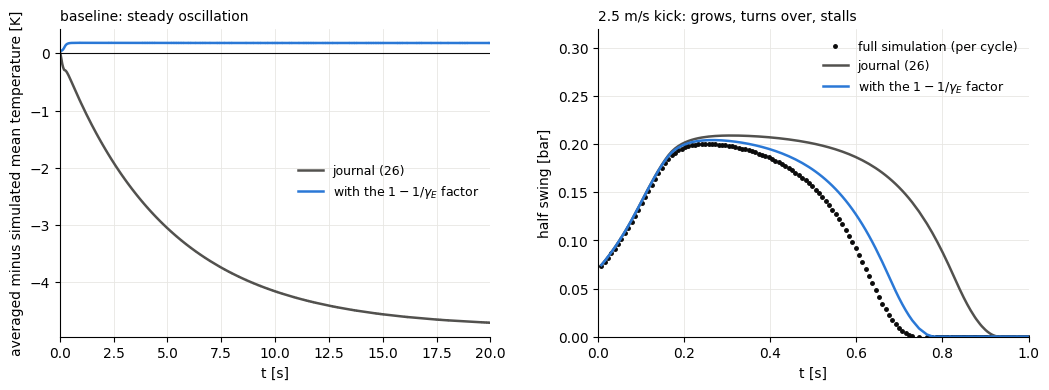

journal (26)                     T_bar error at 1 / 5 / 20 s: -0.88 / -3.06 / -4.71 K;  steady swing 0.2945 bar (simulated 0.2946);  stall run envelope error (rms, % of the largest swing): 28.9
with the (1 - 1/gamma_E) factor  T_bar error at 1 / 5 / 20 s: +0.18 / +0.18 / +0.18 K;  steady swing 0.2947 bar (simulated 0.2946);  stall run envelope error (rms, % of the largest swing): 7.6


In [2]:
tic = time.time()
runs = {}
for kw, t_end in [(dict(), 20.0), (dict(v0=2.5), 3.0)]:
    m = Model(**kw); t, Y = m.simulate(m.y0_full(), 0.0, t_end); P, T = m.PT_of(Y)
    tm, Pm, half, Tm = per_cycle(m, t, P, T)
    res = dict(t=t, Y=Y, tm=tm, Pm=Pm, half=half, Tm=Tm)
    for corr in (False, True):
        mc = Model(corr=corr, **kw); sol = mc.run_avg(t_end); Pb, dd, Tb = mc.observe(sol, tm)
        res[corr] = dict(Pb=Pb, d=dd, Tb=Tb)
    runs[t_end] = res
    print('%-14s simulated %.0f s  [%.0f s]' % (kw or 'baseline', t_end, time.time() - tic), flush=True)

base, stall = runs[20.0], runs[3.0]
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.0)); fig.subplots_adjust(wspace=0.25)
ax = axs[0]
for corr, col, lab in ((False, INK2, 'journal (26)'), (True, BLUE, 'with the $1 - 1/\\gamma_E$ factor')):
    ax.plot(base['tm'], base[corr]['Tb'] - base['Tm'], color=col, lw=1.8, label=lab)
ax.axhline(0, color=INK, lw=0.8); ax.set_xlim(0, 20); ax.set_xlabel('t [s]')
ax.set_ylabel('averaged minus simulated mean temperature [K]'); ax.set_title('baseline: steady oscillation', fontsize=10, loc='left')
ax.legend(frameon=False, fontsize=9); style(ax)
ax = axs[1]
ax.plot(stall['tm'], stall['half'] / 1e5, 'o', ms=2.5, color=INK, label='full simulation (per cycle)')
for corr, col, lab in ((False, INK2, 'journal (26)'), (True, BLUE, 'with the $1 - 1/\\gamma_E$ factor')):
    ax.plot(stall['tm'], stall[corr]['d'] / 1e5, color=col, lw=1.8, label=lab)
ax.set_xlim(0, 1.0); ax.set_ylim(0, 0.32); ax.set_xlabel('t [s]'); ax.set_ylabel('half swing [bar]')
ax.set_title('2.5 m/s kick: grows, turns over, stalls', fontsize=10, loc='left'); ax.legend(frameon=False, fontsize=9); style(ax)
plt.show()

for corr in (False, True):
    sel = [np.argmin(np.abs(base['tm'] - tt)) for tt in (1.0, 5.0, 20.0)]
    e = 100 * np.sqrt(np.mean((stall[corr]['d'] - stall['half']) ** 2)) / stall['half'].max()
    print('%-32s T_bar error at 1 / 5 / 20 s: %+.2f / %+.2f / %+.2f K;  steady swing %.4f bar (simulated %.4f);  stall run envelope error (rms, %% of the largest swing): %.1f'
          % ('journal (26)' if not corr else 'with the (1 - 1/gamma_E) factor', *[base[corr]['Tb'][i] - base['Tm'][i] for i in sel], base[corr]['d'][-1] / 1e5, base['half'][-20:].mean() / 1e5, e))

In [3]:
# the 37 settings of the sweep notebooks: steady/stall outcome of the averaged model against the simulation
tic = time.time(); rows = []
for key, (label, vals) in SWEEPS.items():
    for v in vals:
        m = Model(**{key: v}); te = t_end_for(m)
        t, P, T = m.run_full(te); tm, Pm, half, Tm = per_cycle(m, t, P, T)
        late = tm > te - 0.1; sim = 'steady' if (late.any() and half[late].mean() > 1e3) else 'stall'
        r = dict(sweep=key, value=v, simulation=sim)
        for corr in (False, True):
            mc = Model(corr=corr, **{key: v}); sol = mc.run_avg(te); Pb, dd, Tb = mc.observe(sol, np.array([te - 1e-3]))
            r['journal (26)' if not corr else 'with factor'] = 'steady' if dd[0] > 1e3 else 'stall'
        rows.append(r)
df = pd.DataFrame(rows)
for col in ('journal (26)', 'with factor'):
    miss = df[df[col] != df['simulation']]
    print('%-14s outcome agrees with the simulation in %d of 37;  misses: %s' % (col, (df[col] == df['simulation']).sum(), ', '.join('%s = %g' % (a, b) for a, b in zip(miss['sweep'], miss['value'])) or 'none'))
print('[%.0f s]' % (time.time() - tic))

# the smallest kick that survives (bisection on v0)
def steady_full(v0, t_end=3.0):
    m = Model(v0=v0); t, P, T = m.run_full(t_end); tm, Pm, half, Tm = per_cycle(m, t, P, T)
    late = tm > t_end - 0.1
    return bool(late.any() and half[late].mean() > 1e3)

def steady_avg(v0, corr, t_end=3.0):
    m = Model(v0=v0, corr=corr); sol = m.run_avg(t_end); Pb, dd, Tb = m.observe(sol, np.array([t_end - 1e-3]))
    return bool(dd[0] > 1e3)

def bisect(is_steady, lo, hi, tol):
    while hi - lo > tol:
        mid = 0.5 * (lo + hi); lo, hi = (lo, mid) if is_steady(mid) else (mid, hi)
    return lo, hi

tic = time.time()
thr = {'full simulation': bisect(steady_full, 2.3, 2.9, 0.01), 'averaged, journal (26)': bisect(lambda v: steady_avg(v, False), 1.5, 4.0, 0.002),
       'averaged, with factor': bisect(lambda v: steady_avg(v, True), 1.5, 4.0, 0.002)}
for k, (lo, hi) in thr.items():
    print('%-26s kick threshold %.3f - %.3f m/s' % (k, lo, hi))
print('[%.0f s]' % (time.time() - tic))

journal (26)   outcome agrees with the simulation in 37 of 37;  misses: none
with factor    outcome agrees with the simulation in 37 of 37;  misses: none
[346 s]


full simulation            kick threshold 2.619 - 2.628 m/s
averaged, journal (26)     kick threshold 2.525 - 2.527 m/s
averaged, with factor      kick threshold 2.586 - 2.588 m/s
[78 s]


## 2. The steady oscillation as a fixed point of the slow equations

The slow system is

$$\frac{d\bar M}{dt} = \dot m_{0,in} - \dot m_{0,out} \equiv F_M(\bar P, \delta), \qquad \frac{d\bar P}{dt} = F_P(\bar M, \bar P, \delta), \qquad \frac{da}{dt} = \lambda(\bar M, \bar P, \delta)  a, \qquad \delta = \frac{k_{cv}(\bar P)  a}{A},$$

with $\bar M$ entering $F_P$ and $\lambda$ only through $\bar T = \bar P \bar V_{cv}/\bar M R$. A steady oscillation is a point $(\bar M^*, \bar P^*, a^*)$ where all three right-hand sides vanish: the mass balance $\dot m_{0,in} = \dot m_{0,out}$ fixes $\bar P^*$, the growth-rate condition $\lambda = 0$ (that is, $g^* = (b/m)/f$) fixes $\delta^*$, and $d\bar P/dt = 0$ fixes $\bar T^*$ and hence $\bar M^*$. `fixed_point` finds it with a root finder started from a 3 s run.

For identical reeds the mass balance has a symmetry: at $\bar P = P_b = (P_{in} + P_{out})/2$ the inlet sees $\Delta P_{in}(\psi) = \Delta \bar P - \delta\cos\psi$ and the outlet $\Delta P_{out}(\psi) = \Delta\bar P + \delta\cos\psi$ with the same $\Delta\bar P$, so $\dot m_{0,in} = \dot m_{0,out}$ at $P_b$ for every $\delta$ — the pure-cosine averaged model puts the steady mean exactly at $P_b$, whatever the swing. The simulated mean sits 9 mbar lower, and the cell shows why: the simulated waveform has a second harmonic of 2.6 percent, in phase with the fundamental, which raises both the peaks and the troughs relative to the mean and breaks the symmetry; the rectified flows balance at the simulated mean once that harmonic is included. This offset returns in section 6.

In [4]:
m = Model(); ys = m.fixed_point(); Tb_star, d_star = m.state(ys)
Vp, Vc, kcv, kp, w0 = m.geom(ys[1]); f_star = kcv / (kcv + kp)
lam, g_star, dMb, dPb, w = m.rates(ys[1], Tb_star, d_star)
F0i, Ni = m.inlet(ys[1], d_star); F0o, H0o, Go = m.outlet(ys[1], Tb_star, d_star)
P_b = 0.5 * (m.P_in + m.P_out)
print('fixed point of the averaged model:  P_bar* = %.4f bar (P_b = %.4f),  delta* = %.4f bar,  T_bar* = %.2f K,  M_bar* = %.4f g,  a* = %.1f mm,  f = %.1f Hz'
      % (ys[1] / 1e5, P_b / 1e5, d_star / 1e5, Tb_star, ys[0] * 1e3, ys[2] * 1e3, w0 / 2 / np.pi))
print('   residuals: lambda %.1e 1/s, dM/dt %.1e kg/s, dP/dt %.1e Pa/s;  g* = %.4f = (b/m)/f = %.4f;  throughflow %.4f g/s, exchanged per cycle %.2f%% of the CV mass'
      % (lam, dMb, dPb, g_star, m.b_gas / m.m_gas / f_star, F0o * 1e3, 100 * F0o / (w0 / 2 / np.pi) / ys[0]))
plateau = base['tm'] > 19.5
print('full simulation at 19.5-20 s:        P_bar  = %.4f bar,  delta  = %.4f bar,  T_bar  = %.2f K' % (base['Pm'][plateau].mean() / 1e5, base['half'][plateau].mean() / 1e5, base['Tm'][plateau].mean()))

# the second harmonic of the simulated waveform and the mean it implies
t, Y = base['t'], base['Y']; x, v, M, E = Y; P, T = m.PT_of(Y)
up = np.where((v[:-1] < 0) & (v[1:] >= 0))[0]; up = up[t[up] > 19.5]
rows = []
for a, b in zip(up[:-1], up[1:]):
    Pc = P[a:b]; ph = 2 * np.pi * (t[a:b] - t[a]) / (t[b] - t[a]); Pbar = Pc.mean()
    c1, s1 = 2 * np.mean((Pc - Pbar) * np.cos(ph)), 2 * np.mean((Pc - Pbar) * np.sin(ph))
    c2, s2 = 2 * np.mean((Pc - Pbar) * np.cos(2 * ph)), 2 * np.mean((Pc - Pbar) * np.sin(2 * ph))
    rows.append((Pbar, np.hypot(c1, s1), np.hypot(c2, s2), np.arctan2(s2, c2) - 2 * np.arctan2(s1, c1)))
Pbar_sim, d1, d2, rel2 = np.array(rows).mean(axis=0)
psi = np.linspace(0, 2 * np.pi, 4097)[:-1]
def net_flow(Pb, with_second):
    wave = Pb + d1 * np.cos(psi) + (d2 * np.cos(2 * psi + rel2) if with_second else 0.0)
    return (m.reed_vec(m.P_in - wave) - m.reed_vec(wave - m.P_out)).mean()
P_bal1 = brentq(lambda p: net_flow(p, False), 5.65e5, 5.8e5); P_bal2 = brentq(lambda p: net_flow(p, True), 5.65e5, 5.8e5)
print('simulated waveform: fundamental %.4f bar, second harmonic %.4f bar (%.1f%%, phase %.2f rad relative to the fundamental)' % (d1 / 1e5, d2 / 1e5, 100 * d2 / d1, rel2))
print('mean pressure at which the rectified flows balance: pure cosine %.4f bar;  cosine + second harmonic %.4f bar;  simulated %.4f bar' % (P_bal1 / 1e5, P_bal2 / 1e5, Pbar_sim / 1e5))

fixed point of the averaged model:  P_bar* = 5.7250 bar (P_b = 5.7250),  delta* = 0.2947 bar,  T_bar* = 299.05 K,  M_bar* = 0.6629 g,  a* = 13.0 mm,  f = 128.3 Hz
   residuals: lambda 4.7e-15 1/s, dM/dt -2.2e-19 kg/s, dP/dt -9.6e-11 Pa/s;  g* = 5.0135 = (b/m)/f = 5.0135;  throughflow 0.1351 g/s, exchanged per cycle 0.16% of the CV mass
full simulation at 19.5-20 s:        P_bar  = 5.7163 bar,  delta  = 0.2946 bar,  T_bar  = 298.88 K
simulated waveform: fundamental 0.2945 bar, second harmonic 0.0076 bar (2.6%, phase 0.03 rad relative to the fundamental)
mean pressure at which the rectified flows balance: pure cosine 5.7250 bar;  cosine + second harmonic 5.7163 bar;  simulated 5.7163 bar


## 3. Three cycle averages of the reed slope

**The reed law with backflow and its slope.** With $u = \Delta P/\Delta P_{max}$, the law of `reed_flow` is $\dot m = c_1\dot m_{max}(1-u)\sqrt{u}$ for $0 < u < 1$, $\dot m = -c_1\dot m_{max}(1-u)\sqrt{|u|}$ for $u \le 0$ (backflow) and $0$ for $u \ge 1$ (pressed shut); $c_1\dot m_{max}$ is `m_max` of the code. Its local slope is the same expression on both open branches,

$$\dot m'(\Delta P) = \frac{d\dot m}{d\Delta P} = -\frac{c_1\dot m_{max}}{2\Delta P_{max}}\tilde h(u), \qquad \tilde h(u) = \frac{3u-1}{\sqrt{|u|}} \ (u < 1), \qquad \tilde h(u) = 0 \ (u \ge 1),$$

where $\tilde h$ is the drive function $h(u)$ of (32a) extended to the backflow branch. There it is negative: a reversed reed is a leak whose flow rises with the pressure drop, a positive conductance, which damps. $\tilde h$ is positive only on the falling branch $1/3 < u < 1$. Along a cycle $u_{in}(\psi) = (P_{in} - \bar P - \delta\cos\psi)/\Delta P_{max}$ and $u_{out}(\psi) = (\bar P - P_{out} + \delta\cos\psi)/\Delta P_{max}$; $\langle\cdot\rangle$ is the cycle average $\frac{1}{2\pi}\int_0^{2\pi}d\psi$.

**(a) The gain at any amplitude.** Integrate the first-harmonic integral (16) by parts ($\dot m$ is continuous, so there are no boundary terms and no jumps to collect): $\dot m_{1,out} = \frac{1}{\pi}\int\dot m(\Delta\bar P_{out} + \delta\cos\psi)\cos\psi  d\psi = \frac{\delta}{\pi}\int \dot m'_{out}\sin^2\psi  d\psi$, and the inlet the same with the opposite sign. So $N_{out} = 2\langle\dot m'_{out}\sin^2\psi\rangle$, $N_{in} = -2\langle\dot m'_{in}\sin^2\psi\rangle$, and with $\bar T = T_{in}$ the gain (17) and the growth rate (20) become

$$\lambda = \Lambda\left[X(\bar P,\delta) - X^*\right], \qquad X(\bar P,\delta) = 2\left\langle\left[\tilde h(u_{in}(\psi)) + \tilde h(u_{out}(\psi))\right]\sin^2\psi\right\rangle,$$

with $\Lambda$ and $X^*$ of (32b): the small-signal form (32a) holds at any amplitude once $h(u_{in}) + h(u_{out})$ is replaced by this weighted average. It reduces to (32a) as $\delta \to 0$ because $2\langle\sin^2\psi\rangle = 1$. The steady swing is where $X(\bar P^*, \delta^*) = X^*$. Physically: the gain is the drive $\tilde h$ averaged with the weight $2\sin^2\psi$, which is 2 at mid-swing and 0 at the extremes.

**(b) The amplitude derivative.** Differentiate (16) under the integral sign: $d\dot m_{1,out}/d\delta = \frac{1}{\pi}\int\dot m'_{out}\cos^2\psi  d\psi$. Subtract $N_{out} = \dot m_{1,out}/\delta$ and use $\cos^2\psi - \sin^2\psi = \cos 2\psi$:

$$\delta\frac{\partial X}{\partial\delta} = 2\left\langle\left[\tilde h(u_{in}) + \tilde h(u_{out})\right]\cos 2\psi\right\rangle.$$

The weight $\cos 2\psi$ is $+1$ at both extremes of the swing and $-1$ at mid-swing. The gain falls with amplitude exactly when the reeds drive less at the extremes than at mid-swing — which is what being pressed shut ($\tilde h = 0$) or reversed ($\tilde h < 0$) at the extremes does.

**(c) The mass balance at any amplitude.** Differentiating the mean-flow integrals (16) with respect to $\bar P$ gives $\partial\dot m_{0,out}/\partial\bar P = \langle\dot m'_{out}\rangle$ and $\partial\dot m_{0,in}/\partial\bar P = -\langle\dot m'_{in}\rangle$, so

$$\frac{\partial\left(\dot m_{0,in} - \dot m_{0,out}\right)}{\partial\bar P} = \frac{c_1\dot m_{max}}{2\Delta P_{max}}X_0(\bar P,\delta), \qquad X_0 = \left\langle\tilde h(u_{in}) + \tilde h(u_{out})\right\rangle,$$

which is (29) at any amplitude. At $\delta = 0$, $X_0 = X > X^* > 0$ inside the window: the balance is unstable, the runaway of section 9.4. At the steady swing $X_0$ has the opposite sign (next cell), so the oscillation turns the balance pressure into a stable point. With the adiabatic outlet temperature the outlet's $\tilde h$ carries the factor $T(\psi)/\bar T$ and the extra term of (32b') of the adiabatic note; the code (`slope_local`) includes both, and the numbers below are with them.

The cell checks the three identities against the model's own integrals and finite differences at the fixed point, then plots $\lambda$, $\delta \partial X/\partial\delta$ and $X_0$ against the swing at $\bar P = \bar P^*$, with and without the backflow branch. Note the integrable $1/\sqrt{|u|}$ singularity of the slope where a reed opens or reverses: the averages are evaluated on a fine phase grid, and the finite differences of the 512-point integrals use a step that spans several grid points.

reed law,with backflow,one-sided law (6)
delta* [bar],0.2947,0.3336
"g at the fixed point, from (16) [1/s]",5.0135,5.0135
g from 2<s sin^2 psi> [1/s],5.0163,5.0370
"delta dg/ddelta, finite difference [1/s]",-79.4611,-18.6987
delta dg/ddelta from 2<s cos 2psi> [1/s],-79.3358,-18.3942
"d(m0_in - m0_out)/dP, finite difference [g/s per bar]",-2.8611,-0.3451
the same from <s> [g/s per bar],-2.8526,-0.3431
X(delta*),0.3761,0.3776
X* = b/(2 m Lambda),0.3759,0.3759
delta dX/ddelta at delta*,-5.9479,-1.3790


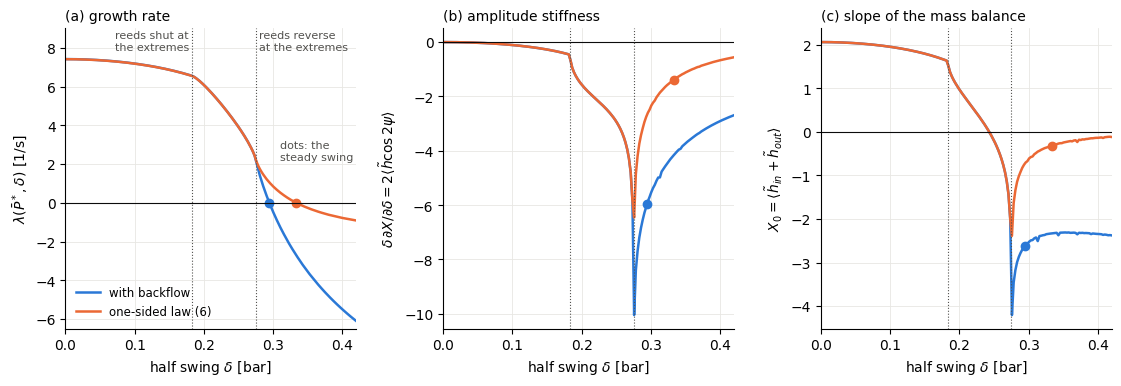

In [5]:
def fine_psi(n=2 ** 18):
    return (np.arange(n) + 0.5) * (2 * np.pi / n)

def mass_slope_fine(m, Pb, delta, n=2 ** 18):
    """X_0 = <h_in + h_out>: the slope of the net rectified inflow in units of c_1 mdot_max / 2 dP_max, on a fine phase grid."""
    P = Pb + delta * np.cos(fine_psi(n)); unit = m.m_max / (2 * m.dP_max)
    return -(m.slope_vec(m.P_in - P).mean() + m.slope_vec(P - m.P_out).mean()) / unit

def net_flow_fine(m, Pb, delta, n=2 ** 18):
    P = Pb + delta * np.cos(fine_psi(n))
    return (m.reed_vec(m.P_in - P) - m.reed_vec(P - m.P_out)).mean()

def closed_forms(m, ys):
    """Lambda, X*, and at the fixed point: X, delta dX/ddelta (temperature weights included) and X_0."""
    Tb, dl = m.state(ys); Vp, Vc, kcv, kp, w = m.geom(ys[1]); f = kcv / (kcv + kp)
    unit = m.m_max / (2 * m.dP_max); Lam = 0.5 * f * (m.Cf * m.T_in / Vc) * unit
    sa = m.slope_averages_fine(ys[1], Tb, dl)
    X = -(sa['in'][1] + sa['out'][1] * Tb / m.T_in) / unit; dX = -(sa['in'][2] + sa['out'][2] * Tb / m.T_in) / unit
    return dict(Lam=Lam, Xstar=m.b_gas / (2 * m.m_gas * Lam), X=X, dX=dX, X0=mass_slope_fine(m, ys[1], dl), kappa=m.gamma_E * Vp / (2 * m.gamma * Vc), f=f, unit=unit)

rows = []
for kw, lab in [(dict(), 'with backflow'), (dict(backflow=False), 'one-sided law (6)')]:
    m = Model(**kw); ys = m.fixed_point(); Tb, dl = m.state(ys); Vp, Vc, kcv, kp, w = m.geom(ys[1])
    cf = closed_forms(m, ys); sa = m.slope_averages_fine(ys[1], Tb, dl)
    lam, g, dMb, dPb, w = m.rates(ys[1], Tb, dl)
    g_formula = -(m.Cf / Vc) * (m.T_in * sa['in'][1] + Tb * sa['out'][1])
    dg_formula = -(m.Cf / Vc) * (m.T_in * sa['in'][2] + Tb * sa['out'][2])
    h = 0.01 * dl; dg_fd = (m.rates(ys[1], Tb, dl + h)[1] - m.rates(ys[1], Tb, dl - h)[1]) / (2 * h) * dl
    hP = 20.0; sM_fd = (net_flow_fine(m, ys[1] + hP, dl) - net_flow_fine(m, ys[1] - hP, dl)) / (2 * hP)
    rows.append({'reed law': lab, 'delta* [bar]': dl / 1e5, 'g at the fixed point, from (16) [1/s]': g, 'g from 2<s sin^2 psi> [1/s]': g_formula,
                 'delta dg/ddelta, finite difference [1/s]': dg_fd, 'delta dg/ddelta from 2<s cos 2psi> [1/s]': dg_formula,
                 'd(m0_in - m0_out)/dP, finite difference [g/s per bar]': sM_fd * 1e8, 'the same from <s> [g/s per bar]': cf['unit'] * cf['X0'] * 1e8,
                 'X(delta*)': cf['X'], 'X* = b/(2 m Lambda)': cf['Xstar'], 'delta dX/ddelta at delta*': cf['dX'], 'X_0 at delta*': cf['X0'],
                 'X_0 at delta = 0': -(m.slope(m.P_in - ys[1]) + m.slope(ys[1] - m.P_out)) / cf['unit']})
display(pd.DataFrame(rows).set_index('reed law').T.round(4))

# the three averages against the swing, at the fixed point's mean and temperature
fig, axs = plt.subplots(1, 3, figsize=(13.5, 3.9)); fig.subplots_adjust(wspace=0.3)
dgrid = np.linspace(1.0, 0.42e5, 170)
for kw, col, lab in [(dict(), BLUE, 'with backflow'), (dict(backflow=False), ORANGE, 'one-sided law (6)')]:
    m = Model(**kw); ys = m.fixed_point(); Tb, dl = m.state(ys); cf = closed_forms(m, ys)
    lam_d = np.array([m.rates(ys[1], Tb, d)[0] for d in dgrid])
    dX = np.array([-(s['in'][2] + s['out'][2] * Tb / m.T_in) / cf['unit'] for s in (m.slope_averages_fine(ys[1], Tb, d, n=2 ** 18) for d in dgrid)])
    X0 = np.array([mass_slope_fine(m, ys[1], d) for d in dgrid])
    for ax, y in zip(axs, (lam_d, dX, X0)):
        ax.plot(dgrid / 1e5, y, color=col, lw=1.8, label=lab); ax.plot(dl / 1e5, np.interp(dl, dgrid, y), 'o', color=col, ms=6)
m = Model(); d_shut = (m.dP_max - 0.5 * (m.P_in - m.P_out)) / 1e5; d_rev = 0.5 * (m.P_in - m.P_out) / 1e5
for ax, ttl, yl in zip(axs, ('(a) growth rate', '(b) amplitude stiffness', '(c) slope of the mass balance'),
                       ('$\\lambda(\\bar P^*, \\delta)$ [1/s]', '$\\delta\\,\\partial X/\\partial\\delta = 2\\langle \\tilde h \\cos 2\\psi\\rangle$', '$X_0 = \\langle \\tilde h_{in} + \\tilde h_{out}\\rangle$')):
    ax.axhline(0, color=INK, lw=0.8)
    for xv in (d_shut, d_rev):
        ax.axvline(xv, color=INK2, lw=0.8, ls=':')
    ax.set_xlim(0, 0.42); ax.set_xlabel('half swing $\\delta$ [bar]'); ax.set_ylabel(yl); ax.set_title(ttl, fontsize=10, loc='left'); style(ax)
axs[0].set_ylim(-6.5, 9.0)
axs[0].text(d_shut - 0.005, 8.9, 'reeds shut at\nthe extremes', fontsize=8, color=INK2, ha='right', va='top')
axs[0].text(d_rev + 0.005, 8.9, 'reeds reverse\nat the extremes', fontsize=8, color=INK2, ha='left', va='top')
axs[0].legend(frameon=False, fontsize=8.5, loc='lower left'); axs[0].text(0.31, 2.2, 'dots: the\nsteady swing', fontsize=8, color=INK2)
plt.show()

## 4. Linear stability: three rates

Linearize the slow system at the fixed point. With $\lambda^* = 0$ the Jacobian in the coordinates $(\bar M, \bar P, a)$ is

$$J = \begin{pmatrix} 0 & \partial F_M/\partial\bar P & \partial F_M/\partial a \\ \partial F_P/\partial\bar M & \partial F_P/\partial\bar P & \partial F_P/\partial a \\ a^*\partial\lambda/\partial\bar M & a^*\partial\lambda/\partial\bar P & a^*\partial\lambda/\partial a\end{pmatrix},$$

and the steady oscillation is stable when all three eigenvalues have negative real parts. The first entry is zero exactly (the mass equation contains no temperature), and for identical reeds $\partial F_M/\partial a = 0$ at $\bar P^* = P_b$ by the symmetry of section 2. Three entries have closed forms from section 3:

- **amplitude:** $\sigma_a \equiv a^* \partial\lambda/\partial a = \delta^* \partial\lambda/\partial\delta = \Lambda \delta \partial X/\partial\delta = 2\Lambda\left\langle(\tilde h_{in} + \tilde h_{out})\cos 2\psi\right\rangle$;
- **mean pressure:** $\sigma_P \equiv \partial F_P/\partial\bar P \approx \frac{c^2}{\bar V_{cv} + \bar V_{pass}} \frac{\partial(\dot m_{0,in} - \dot m_{0,out})}{\partial\bar P} = \frac{\Lambda}{\kappa}X_0$, the drift rate of (31) with the mass-balance slope at the steady swing (the rest of $\partial F_P/\partial\bar P$ is the $\bar P$-dependence of the $\delta^2$ term);
- **mean temperature:** once the two fast modes have relaxed, $\bar P$ follows $\bar M$ quasi-statically through $F_P = 0$, and the mass equation alone is left. Since $F_P$ depends on $\bar M$ only through $\bar T \propto 1/\bar M$ in the enthalpy flux, $\partial F_P/\partial\bar M = (\gamma R/(\bar V_{cv} + \bar V_{pass})) (\bar T/\bar M) \dot m_{0,out}$ while $\partial F_P/\partial\bar P \approx (\gamma R\bar T/(\bar V_{cv} + \bar V_{pass})) \partial F_M/\partial\bar P$, so $d\bar P_{qs}/d\bar M = -\dot m_{0,out}/(\bar M \partial F_M/\partial\bar P)$ and the rate of the slow mode is $\sigma_T = (\partial F_M/\partial\bar P) (d\bar P_{qs}/d\bar M) = -\dot m_{0,out}/\bar M$: the CV is flushed by the throughflow, whatever the reeds' slope.

At the steady swing (section 3) $\delta \partial X/\partial\delta < 0$ and $X_0 < 0$, so all three rates are negative and the fixed point is stable. The cell evaluates the Jacobian by finite differences (steps that span several points of the phase grid), its eigenvalues and eigenvectors, and compares them with the three closed forms — for the model as set up, without the backflow branch, with $\bar T$ at the outlet, and with the journal's (26).

In [6]:
rows = []; fixed = {}
for kw, lab in [(dict(), 'model as set up'), (dict(backflow=False), 'one-sided reed law (6)'), (dict(mode='Tbar'), 'T_bar at the outlet'), (dict(corr=False), "journal's (26)")]:
    m = Model(**kw); ys = m.fixed_point(); Tb, dl = m.state(ys); cf = closed_forms(m, ys); fixed[lab] = (m, ys)
    F0o = m.outlet(ys[1], Tb, dl)[0]
    J = m.jacobian(ys); ev, V = np.linalg.eig(J); order = np.argsort(ev.real)
    # mode shapes in relative coordinates (dM/M, dP/P, da/a), normalized to the largest component
    shapes = []
    for i in order:
        v = np.real(V[:, i]) / np.array([ys[0], ys[1], ys[2]]); v = v / v[np.argmax(np.abs(v))]; shapes.append(v)
    rows.append({'': lab, 'delta* [bar]': dl / 1e5, 'eigenvalue 1 [1/s]': ev[order[0]].real, 'eigenvalue 2 [1/s]': ev[order[1]].real, 'eigenvalue 3 [1/s]': ev[order[2]].real,
                 'sigma_a = Lambda delta dX/ddelta [1/s]': cf['Lam'] * cf['dX'], 'J_aa [1/s]': J[2, 2],
                 'sigma_P = (Lambda/kappa) X_0 [1/s]': cf['Lam'] / cf['kappa'] * cf['X0'], 'J_PP [1/s]': J[1, 1],
                 'sigma_T = -m0_out/M [1/s]': -F0o / ys[0],
                 'mode 1 (dM/M, dP/P, da/a)': np.array2string(shapes[0], precision=3, suppress_small=True),
                 'mode 2 (dM/M, dP/P, da/a)': np.array2string(shapes[1], precision=3, suppress_small=True),
                 'mode 3 (dM/M, dP/P, da/a)': np.array2string(shapes[2], precision=3, suppress_small=True)})
tab = pd.DataFrame(rows).set_index('').T
display(tab)
m, ys = fixed['model as set up']; J = m.jacobian(ys)
print('Jacobian of the model as set up (rows dM/dt, dP/dt, da/dt; columns M, P, a):'); print(np.array2string(J, precision=4, suppress_small=True))

,model as set up,one-sided reed law (6),T_bar at the outlet,journal's (26)
delta* [bar],0.294677,0.333566,0.294726,0.294524
eigenvalue 1 [1/s],-26.410931,-6.21234,-26.650162,-26.187132
eigenvalue 2 [1/s],-11.393969,-1.441347,-11.476104,-11.370863
eigenvalue 3 [1/s],-0.204619,-0.195648,-0.201954,-0.200601
sigma_a = Lambda delta dX/ddelta [1/s],-26.374252,-6.114936,-26.489761,-26.206696
J_aa [1/s],-26.409903,-6.21235,-26.646991,-26.186156
sigma_P = (Lambda/kappa) X_0 [1/s],-11.688491,-1.405839,-11.686907,-12.091816
J_PP [1/s],-11.599616,-1.636984,-11.681228,-11.57244
sigma_T = -m0_out/M [1/s],-0.203736,-0.195321,-0.202921,-0.20077
"mode 1 (dM/M, dP/P, da/a)",[-0. -0. 1.],[-0. -0. 1.],[-0. -0. 1.],[-0.001 -0.001 1. ]


Jacobian of the model as set up (rows dM/dt, dP/dt, da/dt; columns M, P, a):
[[       0.           -0.            0.    ]
 [83212117.4549      -11.5996   130776.5966]
 [     -16.3166        0.          -26.4099]]


## 5. Perturbing the steady oscillation: full simulation against the averaged model

**The perturbation.** In the full simulation the baseline is run to 1.5 s, by which time it is on its steady oscillation. At that instant the oscillating part of the state is scaled: with $\bar x$ and $\bar E$ the means of the piston position and the CV energy over the last cycle, $x \to \bar x + \eta(x - \bar x)$, $v \to \eta v$, $E \to \bar E + \eta(E - \bar E)$, and $M$ unchanged. Because the sealed-cycle relations between $x'$, $P'$ and $T'$ are linear and homogeneous, this multiplies the swing by $\eta$ while leaving the mean pressure, the mean temperature and the mass where they were (`perturb_state`). In the averaged model the same thing is $a \to \eta a^*$ at the fixed point.

**What is compared.** The per-cycle half swing of the simulation after the perturbation against $\delta(t)$ of the averaged model started from its perturbed fixed point, for $\eta$ from 0.5 to 3; the rate of return, fitted to $\ln|\delta - \delta_\infty|$ while the deviation decays from a half to a twentieth of its initial value, against the amplitude eigenvalue $\sigma_a$ of section 4; and the same without the backflow branch. A third curve is the one-dimensional prediction with the mean frozen, $d\ln\delta/dt = \lambda(\bar P^*, \delta)$ integrated from $\eta\delta^*$ — if it lies on the averaged model's curve, the mean played no part in the return.

with backflow        steady swing: simulation 0.2946 bar, averaged 0.2947 bar;  sigma_a = -26.4 1/s  [32 s]


one-sided law (6)    steady swing: simulation 0.3343 bar, averaged 0.3336 bar;  sigma_a = -6.2 1/s  [55 s]


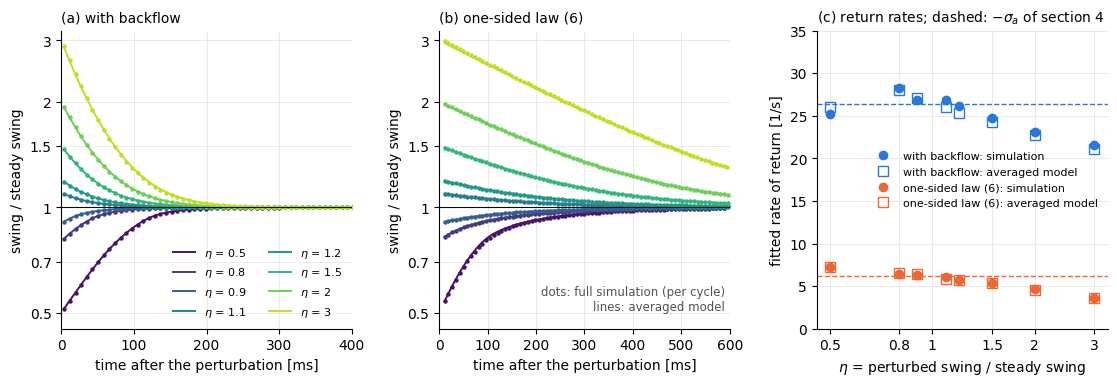

,reed law,eta,"swing at 100 ms, simulation [bar]",averaged [bar],frozen mean [bar],"rate, simulation [1/s]","rate, averaged [1/s]","rate, frozen mean [1/s]",sigma_a [1/s]
0,with backflow,0.5,0.2561,0.2566,0.2566,-25.2202,-26.0459,-26.0442,-26.4099
1,with backflow,0.8,0.2902,0.2903,0.2903,-28.2612,-28.0090,-28.0059,-26.4099
2,with backflow,0.9,0.2927,0.2927,0.2927,-26.8034,-27.0289,-27.0272,-26.4099
3,with backflow,1.1,0.2971,0.2972,0.2972,-26.8224,-25.9675,-25.9665,-26.4099
4,with backflow,1.2,0.3000,0.3002,0.3002,-26.1208,-25.3459,-25.3459,-26.4099
5,with backflow,1.5,0.3107,0.3111,0.3111,-24.6873,-24.2108,-24.2102,-26.4099
6,with backflow,2.0,0.3328,0.3335,0.3335,-23.0789,-22.7818,-22.7810,-26.4099
7,with backflow,3.0,0.3821,0.3840,0.3840,-21.5959,-21.1172,-21.1156,-26.4099
8,one-sided law (6),0.5,0.2689,0.2712,0.2712,-7.2756,-7.2737,-7.2735,-6.2124
9,one-sided law (6),0.8,0.3054,0.3048,0.3048,-6.4497,-6.5780,-6.5780,-6.2124


In [7]:
ETAS = [0.5, 0.8, 0.9, 1.1, 1.2, 1.5, 2.0, 3.0]; T_P = 1.5; T_AFTER = 0.6

def fit_rate(t, d, d_inf, lo=0.5, hi=0.05):
    dev = np.abs(d - d_inf); dev0 = dev[0]
    sel = (dev < lo * dev0) & (dev > hi * dev0)
    if (dev < hi * dev0).any():
        sel &= np.arange(len(t)) < np.argmax(dev < hi * dev0)
    return np.polyfit(t[sel], np.log(dev[sel]), 1)[0] if sel.sum() >= 3 else np.nan

def frozen_mean(m, ys, eta, ta):
    """d ln delta/dt = lambda(P_bar*, delta) at the fixed point's mean and temperature."""
    Tb, dl = m.state(ys)
    sol = solve_ivp(lambda t, y: [m.rates(ys[1], Tb, y[0])[0] * y[0]], (0.0, ta[-1]), [eta * dl], t_eval=ta, rtol=1e-8, atol=1e-3, max_step=2e-3)
    return sol.y[0]

tic = time.time(); pert = {}
for kw, lab in [(dict(), 'with backflow'), (dict(backflow=False), 'one-sided law (6)')]:
    m = Model(**kw); ys = m.fixed_point(); Tb, dl = m.state(ys); J = m.jacobian(ys); sig_a = J[2, 2]
    t, Y = m.simulate(m.y0_full(), 0.0, T_P); P, T = m.PT_of(Y); tm, Pm, half, Tm = per_cycle(m, t, P, T)
    d_inf_sim = half[tm > T_P - 0.3].mean(); out = dict(d_inf_sim=d_inf_sim, dl=dl, sig_a=sig_a, eig=np.sort(np.linalg.eigvals(J).real), runs={})
    for eta in ETAS:
        yp = m.perturb_state(t, Y, eta); t2, Y2 = m.simulate(yp, T_P, T_P + T_AFTER); P2, T2 = m.PT_of(Y2)
        tm2, Pm2, half2, Tm2 = per_cycle(m, t2, P2, T2); ta = tm2 - T_P
        y0 = ys.copy(); y0[2] *= eta; sol = m.run_avg(T_AFTER, y0=y0); Pb, dd, TT = m.observe(sol, ta)
        out['runs'][eta] = dict(ta=ta, sim=half2, avg=dd, frozen=frozen_mean(m, ys, eta, ta), Pm=Pm2, Pb=Pb,
                                r_sim=fit_rate(ta, half2, d_inf_sim), r_avg=fit_rate(ta, dd, dl), r_frozen=fit_rate(ta, frozen_mean(m, ys, eta, ta), dl))
    pert[lab] = out
    print('%-20s steady swing: simulation %.4f bar, averaged %.4f bar;  sigma_a = %.1f 1/s  [%.0f s]' % (lab, d_inf_sim / 1e5, dl / 1e5, sig_a, time.time() - tic), flush=True)

fig, axs = plt.subplots(1, 3, figsize=(13.5, 4.2)); fig.subplots_adjust(wspace=0.3, bottom=0.17)
cols = plt.cm.viridis(np.linspace(0.05, 0.9, len(ETAS)))
for ax, lab, ttl in zip(axs[:2], pert, ('(a) with backflow', '(b) one-sided law (6)')):
    out = pert[lab]
    for eta, col in zip(ETAS, cols):
        r = out['runs'][eta]
        ax.plot(r['ta'] * 1e3, r['sim'] / out['d_inf_sim'], 'o', ms=2.2, color=col)
        ax.plot(r['ta'] * 1e3, r['avg'] / out['dl'], '-', lw=1.4, color=col, label='$\\eta$ = %g' % eta)
    ax.axhline(1, color=INK, lw=0.8); ax.set_xlim(0, 400 if lab == 'with backflow' else 600); ax.set_yscale('log'); ax.set_ylim(0.45, 3.2)
    ax.set_yticks([0.5, 0.7, 1.0, 1.5, 2.0, 3.0]); ax.set_yticklabels(['0.5', '0.7', '1', '1.5', '2', '3']); ax.yaxis.set_minor_locator(plt.NullLocator())
    ax.set_xlabel('time after the perturbation [ms]'); ax.set_ylabel('swing / steady swing'); ax.set_title(ttl, fontsize=10, loc='left'); style(ax)
axs[0].legend(frameon=False, fontsize=8, ncol=2, loc='lower right')
axs[1].text(590, 0.5, 'dots: full simulation (per cycle)\nlines: averaged model', fontsize=8.5, color=INK2, ha='right', va='bottom')
ax = axs[2]
for lab, col in (('with backflow', BLUE), ('one-sided law (6)', ORANGE)):
    out = pert[lab]
    ax.plot(ETAS, [-out['runs'][e]['r_sim'] for e in ETAS], 'o', color=col, ms=6, label=lab + ': simulation')
    ax.plot(ETAS, [-out['runs'][e]['r_avg'] for e in ETAS], 's', mfc='none', color=col, ms=7, label=lab + ': averaged model')
    ax.axhline(-out['sig_a'], color=col, lw=1.0, ls='--')
ax.set_xscale('log'); ax.set_xticks([0.5, 0.8, 1.0, 1.5, 2.0, 3.0]); ax.set_xticklabels(['0.5', '0.8', '1', '1.5', '2', '3']); ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xlabel('$\\eta$ = perturbed swing / steady swing'); ax.set_ylabel('fitted rate of return [1/s]'); ax.set_ylim(0, 35)
ax.set_title('(c) return rates; dashed: $-\\sigma_a$ of section 4', fontsize=10, loc='left'); ax.legend(frameon=False, fontsize=8, loc='center right'); style(ax)
plt.show()

rows = []
for lab in pert:
    for eta in ETAS:
        r = pert[lab]['runs'][eta]; i = np.argmin(np.abs(r['ta'] - 0.1))
        rows.append({'reed law': lab, 'eta': eta, 'swing at 100 ms, simulation [bar]': r['sim'][i] / 1e5, 'averaged [bar]': r['avg'][i] / 1e5, 'frozen mean [bar]': r['frozen'][i] / 1e5,
                     'rate, simulation [1/s]': r['r_sim'], 'rate, averaged [1/s]': r['r_avg'], 'rate, frozen mean [1/s]': r['r_frozen'], 'sigma_a [1/s]': pert[lab]['sig_a']})
display(pd.DataFrame(rows).round(4))

## 6. Large perturbations: how much of the swing can be lost

The linear result says a small perturbation decays; a large loss of amplitude is a different question. Once the swing is small the reeds no longer reach their shut and backflow branches, $X_0$ turns positive again (section 3), and the mean is back on the unstable balance of section 9.4: it runs away from $P_b$ at the rate $(\Lambda/\kappa)X_0(\bar P, 0) \approx 9$ per second while the oscillation regrows at $\lambda_{lin} \approx 7$ per second. The outcome is the race of section 9, and the budget (33) applies with $P_0$ the steady mean: the oscillation survives a sudden drop to $\delta_0$ if $\ln(\delta^*/\delta_0) < B(P_0 = \bar P^*)$.

What decides $B$ is how far $\bar P^*$ sits from $P_b$, because $\dot m_{net}(P_0)$ in the logarithm of (33) vanishes there. The pure-cosine averaged model has $\bar P^* = P_b$ exactly (section 2), so its $B$ is large — the mean has nowhere to run until the temperature term of (26) nudges it — and it survives almost any loss. The full simulation's mean sits 9 mbar below $P_b$ because of its second harmonic, so after a large loss it drains, the inlet reed is pressed shut at $P_{in} - \Delta P_{max}$, and the window is a few tenths of a second long.

The cell finds the smallest surviving fraction $\eta$ by bisection in the full simulation and in the averaged model — from its own fixed point and, to isolate the effect of the offset, from a state with the simulation's mean pressure and temperature — and compares them with $\delta^* e^{-B}$ from (33). The figure shows the two runs that bracket the edge in the simulation, with the averaged model from the simulated mean at the same $\eta$.

== with backflow   steady swing 0.2947 bar; steady mean: averaged 5.7250 bar, simulated 5.7162 bar (P_b 5.7250)
   smallest surviving fraction eta:  averaged model from its fixed point 0.0089-0.0092 (delta_0 = 2.7 mbar);  averaged from the simulated mean 0.094-0.096 (27.9 mbar);  full simulation 0.115-0.119 (34.5 mbar)
   budget (33) from the simulated mean: drains to the inlet-shut pressure 5.5417 bar in t1 = 0.34 s, B = 2.31 -> survives down to delta* e^-B = 29.2 mbar (eta 0.099);  from 1 mbar below P_b: B = 4.07 -> 5.0 mbar   [95 s]


== one-sided law (6)   steady swing 0.3336 bar; steady mean: averaged 5.7250 bar, simulated 5.7115 bar (P_b 5.7250)
   smallest surviving fraction eta:  averaged model from its fixed point 0.0095-0.0099 (delta_0 = 3.2 mbar);  averaged from the simulated mean 0.117-0.119 (39.3 mbar);  full simulation 0.147-0.152 (50.0 mbar)
   budget (33) from the simulated mean: drains to the inlet-shut pressure 5.5417 bar in t1 = 0.29 s, B = 1.96 -> survives down to delta* e^-B = 46.8 mbar (eta 0.140);  from 1 mbar below P_b: B = 4.07 -> 5.7 mbar   [186 s]


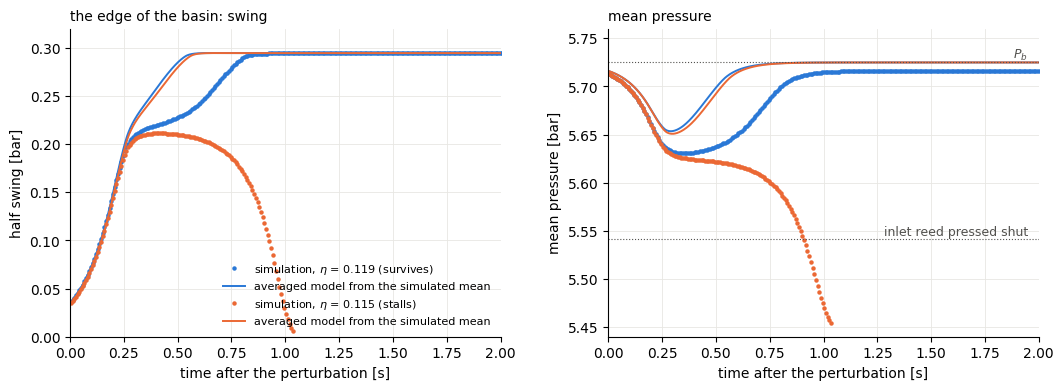

In [8]:
T_P = 1.5; T_LONG = 3.0

def survives_sim(m, t, Y, eta):
    yp = m.perturb_state(t, Y, eta); t2, Y2 = m.simulate(yp, T_P, T_P + T_LONG); P2, T2 = m.PT_of(Y2)
    tm2, Pm2, half2, Tm2 = per_cycle(m, t2, P2, T2); late = tm2 > T_P + T_LONG - 0.2
    return bool(late.any() and half2[late].mean() > 1e4), tm2 - T_P, Pm2, half2

def survives_avg(m, y_start, eta):
    y0 = y_start.copy(); y0[2] *= eta; sol = m.run_avg(T_LONG, y0=y0)
    return bool(m.observe(sol, np.array([T_LONG - 1e-3]))[1][0] > 1e4), sol

def bisect_eta(test, lo, hi, ratio=1.04):
    assert not test(lo)[0] and test(hi)[0]
    while hi / lo > ratio:
        mid = np.sqrt(lo * hi); lo, hi = (lo, mid) if test(mid)[0] else (mid, hi)
    return lo, hi

def budget_from(m, P0, Pstar_geom):
    """B of (33) from P0 along the drift, with the window closing where a reed is pressed shut or lambda_lin = 0."""
    c2 = m.gamma * m.R * m.T_in; Vp, Vc = m.geom(Pstar_geom)[0], m.geom(Pstar_geom)[1]
    f = m.gamma_E * Vp / (m.gamma_E * Vp + m.gamma * Vc); kappa = m.gamma_E * Vp / (2 * m.gamma * Vc); C = (Vc + (m.gamma_E / m.gamma) * Vp) / c2
    mnet = lambda p: m.reed(m.P_in - p) - m.reed(p - m.P_out)
    lam_lin = lambda p: m.rates(p, m.T_in, 0.0)[0]
    step = 1.0 if mnet(P0) > 0 else -1.0; p = P0
    while lam_lin(p + step) > 0:
        p += step
    P1 = p + step; drive = kappa * np.log(mnet(P1 - 0.5 * step) / mnet(P0))
    t1 = abs(C * quad(lambda q: 1.0 / mnet(q), P0, P1 - 0.5 * step, limit=400)[0])
    return drive - m.b_gas / (2 * m.m_gas) * t1, P1, t1

tic = time.time(); basin = {}
for kw, lab in [(dict(), 'with backflow'), (dict(backflow=False), 'one-sided law (6)')]:
    m = Model(**kw); ys = m.fixed_point(); Tb, dl = m.state(ys)
    t, Y = m.simulate(m.y0_full(), 0.0, T_P); P, T = m.PT_of(Y); tm, Pm, half, Tm = per_cycle(m, t, P, T)
    pl = tm > T_P - 0.3; P_sim, T_sim, d_sim = Pm[pl].mean(), Tm[pl].mean(), half[pl].mean()
    y_sim = np.array([P_sim * m.geom(P_sim)[1] / (m.R * T_sim), P_sim, ys[2]])
    e_avg = bisect_eta(lambda e: survives_avg(m, ys, e), 1e-4, 0.5)
    e_avg_sim = bisect_eta(lambda e: survives_avg(m, y_sim, e), 1e-3, 0.5)
    e_sim = bisect_eta(lambda e: survives_sim(m, t, Y, e), 0.01, 0.5)
    B_sim, P1_sim, t1_sim = budget_from(m, P_sim, ys[1]); B_1mbar = budget_from(m, ys[1] - 100.0, ys[1])[0]
    basin[lab] = dict(m=m, t=t, Y=Y, ys=ys, y_sim=y_sim, e_sim=e_sim, d_sim=d_sim, P_sim=P_sim)
    print('== %s   steady swing %.4f bar; steady mean: averaged %.4f bar, simulated %.4f bar (P_b %.4f)' % (lab, dl / 1e5, ys[1] / 1e5, P_sim / 1e5, 0.5 * (m.P_in + m.P_out) / 1e5))
    print('   smallest surviving fraction eta:  averaged model from its fixed point %.4f-%.4f (delta_0 = %.1f mbar);  averaged from the simulated mean %.3f-%.3f (%.1f mbar);  full simulation %.3f-%.3f (%.1f mbar)'
          % (*e_avg, np.sqrt(e_avg[0] * e_avg[1]) * dl / 100, *e_avg_sim, np.sqrt(e_avg_sim[0] * e_avg_sim[1]) * dl / 100, *e_sim, np.sqrt(e_sim[0] * e_sim[1]) * d_sim / 100))
    print('   budget (33) from the simulated mean: drains to the inlet-shut pressure %.4f bar in t1 = %.2f s, B = %.2f -> survives down to delta* e^-B = %.1f mbar (eta %.3f);  from 1 mbar below P_b: B = %.2f -> %.1f mbar   [%.0f s]'
          % (P1_sim / 1e5, t1_sim, B_sim, dl * np.exp(-B_sim) / 100, np.exp(-B_sim), B_1mbar, dl * np.exp(-B_1mbar) / 100, time.time() - tic), flush=True)

# the two runs that bracket the edge, with backflow
b = basin['with backflow']; m, t, Y, y_sim = b['m'], b['t'], b['Y'], b['y_sim']
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.0)); fig.subplots_adjust(wspace=0.25)
for eta, col, lab in ((b['e_sim'][1], BLUE, 'survives'), (b['e_sim'][0], ORANGE, 'stalls')):
    ok, ta, Pm2, half2 = survives_sim(m, t, Y, eta); ok2, sol = survives_avg(m, y_sim, eta)
    tl = np.linspace(0, 2.0, 801); Pb, dd, TT = m.observe(sol, tl); live = half2 > 500.0
    axs[0].plot(ta[live], half2[live] / 1e5, 'o', ms=2.2, color=col, label='simulation, $\\eta$ = %.3f (%s)' % (eta, lab)); axs[0].plot(tl, dd / 1e5, '-', lw=1.4, color=col, label='averaged model from the simulated mean')
    axs[1].plot(ta[live], Pm2[live] / 1e5, 'o', ms=2.2, color=col); axs[1].plot(tl, Pb / 1e5, '-', lw=1.4, color=col)
axs[0].set_ylim(0, 0.32); axs[0].set_ylabel('half swing [bar]'); axs[0].legend(frameon=False, fontsize=8)
axs[1].axhline(0.5 * (m.P_in + m.P_out) / 1e5, color=INK2, lw=0.8, ls=':'); axs[1].text(1.95, 0.5 * (m.P_in + m.P_out) / 1e5 + 0.004, '$P_b$', color=INK2, fontsize=9, ha='right')
axs[1].axhline((m.P_in - m.dP_max) / 1e5, color=INK2, lw=0.8, ls=':'); axs[1].text(1.95, (m.P_in - m.dP_max) / 1e5 + 0.004, 'inlet reed pressed shut', color=INK2, fontsize=9, ha='right')
axs[1].set_ylim(5.44, 5.76); axs[1].set_ylabel('mean pressure [bar]')
for ax in axs:
    ax.set_xlim(0, 2.0); ax.set_xlabel('time after the perturbation [s]'); style(ax)
axs[0].set_title('the edge of the basin: swing', fontsize=10, loc='left'); axs[1].set_title('mean pressure', fontsize=10, loc='left')
plt.show()

## 7. Conclusions

1. **The steady oscillation is stable**, in the averaged model and in the full simulation. It is a fixed point of the three slow equations with three real negative eigenvalues: an amplitude mode at $\sigma_a = \Lambda \delta \partial X/\partial\delta \approx -26$ per second (a time constant of 38 ms, about five cycles), a mean-pressure mode at about $-11$ per second, and a slow thermal mode at $-\dot m_{0,out}/\bar M \approx -0.2$ per second, the flushing of the CV by the throughflow. A sudden change of the swing by a factor between 0.5 and 3 returns along the one-dimensional law $d\ln\delta/dt = \lambda(\bar P^*, \delta)$ with the mean frozen; the simulation's return rates, 25 to 28 per second, agree with $\sigma_a$ and with the averaged model to a few percent, and the simulated swing matches the averaged model's to better than a millibar along the way.

2. **The mechanism is in three cycle averages of one function**, the local slope of the reed law along the cycle, $\tilde h(u)$: with the weight $2\sin^2\psi$ it gives the gain and $\lambda = \Lambda[X - X^*]$ at any amplitude; with the weight $\cos 2\psi$ it gives the amplitude stiffness $\delta \partial X/\partial\delta$; with the weight 1 it gives the slope of the mass balance. At the steady swing both reeds spend about 29 percent of each cycle pressed shut and 12 percent reversed, at the extremes of the swing where $\cos 2\psi = +1$; that is what makes the gain fall with amplitude and what turns the unstable balance pressure of section 9 into a stable one.

3. **The backflow branch is what pins the amplitude.** With the one-sided law (6) the steady swing would be 0.334 instead of 0.295 bar and the amplitude would return four times more slowly ($\sigma_a \approx -6$ per second), with the mean-pressure mode eight times slower. The full simulation with the one-sided law confirms both numbers.

4. **Large losses of amplitude** are a race of the kind of section 9, and the budget (33) with $P_0$ the steady mean predicts the outcome: the simulation survives a drop to 12 percent of the steady swing (35 mbar); the budget from the simulated mean gives 29 mbar. The edge is set by the 9 mbar offset of the steady mean from $P_b$, a consequence of the 2.6 percent second harmonic of the waveform. The pure-cosine averaged model puts the mean exactly at $P_b$ and therefore survives down to 1 percent; started from the simulated mean it gives 9 to 10 percent.

5. **The energy-consistent $\delta^2$ term** (the factor $1 - 1/\gamma_E$ of section 1) does not change the steady swing or mean, but it stops the averaged $\bar T$ from drifting (0.2 K from the simulation at 20 s instead of 4.7 K), improves the stall runs further (the 2.5 m/s kick's envelope error falls from 29 to 8 percent), moves the kick threshold to 2.59 m/s against 2.62 in the simulation, and leaves the outcome right in all 37 settings.